## Coursework Question 2: Minimum Spanning Tree (25 marks)

Code and test one of the Minimum Spanning Tree (MST) algorithms, either Prim’s or Kruskal’s, for a connected NetworkX graph with 6 nodes and 11 edges. You must use the following signature:

    def MyMinimumSpannigTree(Graph) -> Graph

This tells you that your code should contain a function called “MyMinimumSpanningTree” which receives 1 argument in the form of a NetworkX graph, and it returns 1 NetworkX graph.

### Coding

The steps that you must do are below:

a) Create and depict the original connected graph using matplotlib.

b) Call the MyMinimumSpanningTree function.
   - State which MST algorithm you are following.
   - Show the creation of the MST step by step using the console.

c) Depict the final MST using matplotlib.

### Testing

a) Do the same for 2 new graphs that you create. The graphs must be connected and have at least 5 nodes and 8 edges, and be different to the first one and between themselves.

To summarize: in your report you should have images of 3 different graphs with their correspondent 3 different MSTs.

Record yourselves explaining the MST algorithm that you selected, citing your sources. Then, explain the rationale of your code and include a clip of your code running and building the MST step by step for the first graph.

## Q2(a): Create and display the original graph

Plan is to use NetworkX to store the graph and Matplotlib to display it. The graph will have 6 nodes and 11 weighted edges.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
graph = nx.Graph()
edges = [
    ("A", "B", 4),
    ("A", "C", 2),
    ("A", "D", 7),
    ("B", "C", 3),
    ("B", "D", 5),
    ("B", "E", 8),
    ("C", "D", 6),
    ("C", "E", 9),
    ("D", "E", 1),
    ("D", "F", 10),
    ("E", "F", 11)
]
for node1, node2, weight in edges:
    graph.add_edge(node1, node2, weight=weight)
print("Number of nodes:", graph.number_of_nodes())
print("Number of edges:", graph.number_of_edges())
print("Graph is connected:", nx.is_connected(graph))

Number of nodes: 6
Number of edges: 11
Graph is connected: True


The edges are stored in a list of tuples an each tuple contains two nodes and the weight of their connection.

A for loop adds each edge to the graph and then I can check that the graph is connected and contains the required 6 nodes and 11 edges.

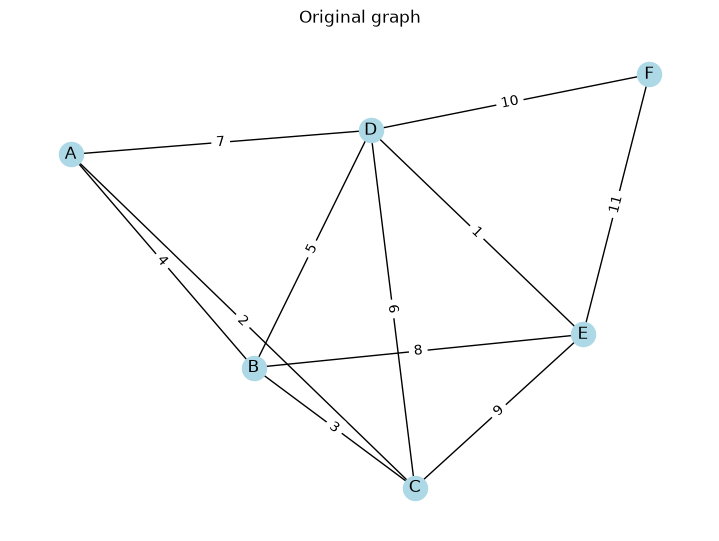

In [3]:
positions = nx.spring_layout(graph, seed=1)
plt.figure(figsize=(7, 5))
nx.draw(graph, positions, with_labels=True, node_color="lightblue")
weights = nx.get_edge_attributes(graph, "weight")
nx.draw_networkx_edge_labels(graph, positions, edge_labels=weights)

plt.title("Original graph")
plt.axis("off")
plt.show()

Each labelled circle represents a node and the lines show the edges, and the numbers show their weights.

note to self. save the node positions so the original graph and its minimum spanning tree can use the same layout.

## Q2(b): Build the minimum spanning tree

Need to use Prim’s algorithm where itstarts at one node and builds the tree one edge at a time.

At each step, it chooses the lowest-weight edge connecting a node already in the tree to a node outside it and then this adds a new node without creating a cycle.

The algorithm stops when all nodes are included. For the first graph, the completed tree will contain 6 nodes and 5 edges.

In [4]:
def MyMinimumSpanningTree(Graph):
    tree = nx.Graph()
    nodes = list(Graph.nodes())
    start = nodes[0]
    visited = [start]
    tree.add_node(start)

    print("Starting node:", start)

    while len(visited) < len(nodes):
        smallest_weight = None
        for node in visited:      
            for neighbour in Graph.neighbors(node):
                if neighbour not in visited:
                    weight = Graph[node][neighbour]["weight"]
                    if smallest_weight is None or weight < smallest_weight:
                        smallest_weight = weight
                        from_node = node
                        to_node = neighbour

        tree.add_edge(from_node, to_node, weight=smallest_weight)
        visited.append(to_node)

        print("Added edge:", from_node, "-", to_node,
              "Weight:", smallest_weight)

    return tree

Prims algo

pass the original graph into the function and store the returned tree in `mst`.

The printed output shows the starting node and each selected edge with its weight.

In [5]:
mst = MyMinimumSpanningTree(graph)

Starting node: A
Added edge: A - C Weight: 2
Added edge: C - B Weight: 3
Added edge: B - D Weight: 5
Added edge: D - E Weight: 1
Added edge: D - F Weight: 10


from the starting node, edges seem to check out correctly. Can test MST

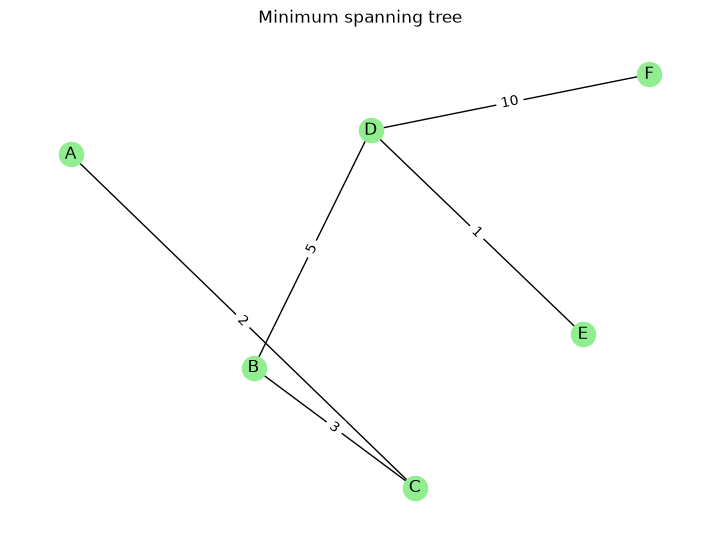

In [6]:
plt.figure(figsize=(7, 5))
nx.draw(mst, positions, with_labels=True, node_color="lightgreen")
weights = nx.get_edge_attributes(mst, "weight")
nx.draw_networkx_edge_labels(mst, positions, edge_labels=weights)
plt.title("Minimum spanning tree")
plt.axis("off")
plt.show()

I check that the tree contains all 6 nodes and has 5 edges and also check that it is connected and has no cycles.

A for loop adds the edge weights together which gives expected total weight of 21.

In [7]:
print("Number of nodes:", mst.number_of_nodes())
print("Number of edges:", mst.number_of_edges())
print("Is a tree:", nx.is_tree(mst))
total_weight = 0

for node1, node2 in mst.edges():
    weight = mst[node1][node2]["weight"]
    total_weight = total_weight + weight
print("Total weight:", total_weight)

Number of nodes: 6
Number of edges: 5
Is a tree: True
Total weight: 21


## Testing: Graph 2

test the same Prim’s algorithm function on a different graph with 5 nodes and 8 weighted edges.

A list of tuples will stores the edges and A for loop adds them to the graph.

In [8]:
graph2 = nx.Graph()
edges2 = [
    ("A", "B", 6),
    ("A", "C", 3),
    ("A", "D", 8),
    ("B", "C", 2),
    ("B", "D", 5),
    ("B", "E", 7),
    ("C", "E", 4),
    ("D", "E", 1)
]
for node1, node2, weight in edges2:
    graph2.add_edge(node1, node2, weight=weight)
print("Number of nodes:", graph2.number_of_nodes())
print("Number of edges:", graph2.number_of_edges())
print("Graph is connected:", nx.is_connected(graph2))

Number of nodes: 5
Number of edges: 8
Graph is connected: True


each tuple , two node names and a weight.

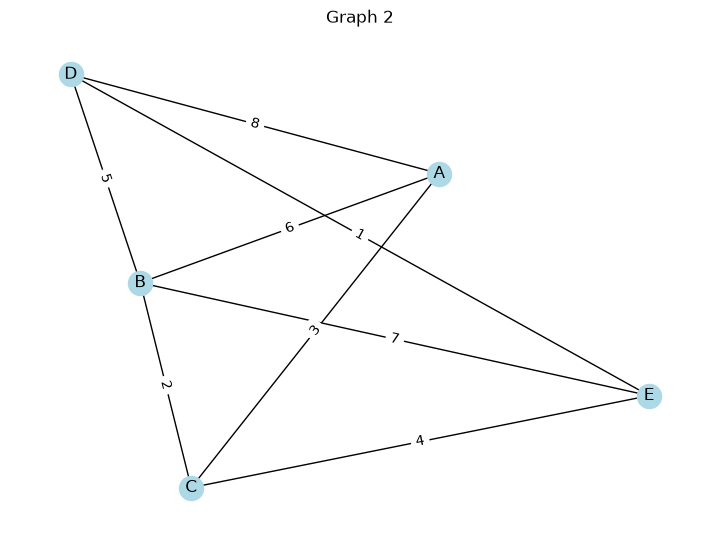

In [10]:
positions2 = nx.spring_layout(graph2, seed=1)
plt.figure(figsize=(7, 5))
nx.draw(graph2, positions2, with_labels=True, node_color="lightblue")
weights2 = nx.get_edge_attributes(graph2, "weight")
nx.draw_networkx_edge_labels(graph2, positions2, edge_labels=weights2)
plt.title("Graph 2")
plt.axis("off")
plt.show()

The diagram shows the second graph and its edge weights. 

saved the node positions so its minimum spanning tree can use the same layout. can run second MST to check edges

In [11]:
mst2 = MyMinimumSpanningTree(graph2)

Starting node: A
Added edge: A - C Weight: 3
Added edge: C - B Weight: 2
Added edge: C - E Weight: 4
Added edge: E - D Weight: 1


### Display the minimum spanning tree for Graph 2

the tree returned by the function, with the weight of each selected edge and the nodes stay in the same positions as the original graph so the two diagrams are easier to compare.

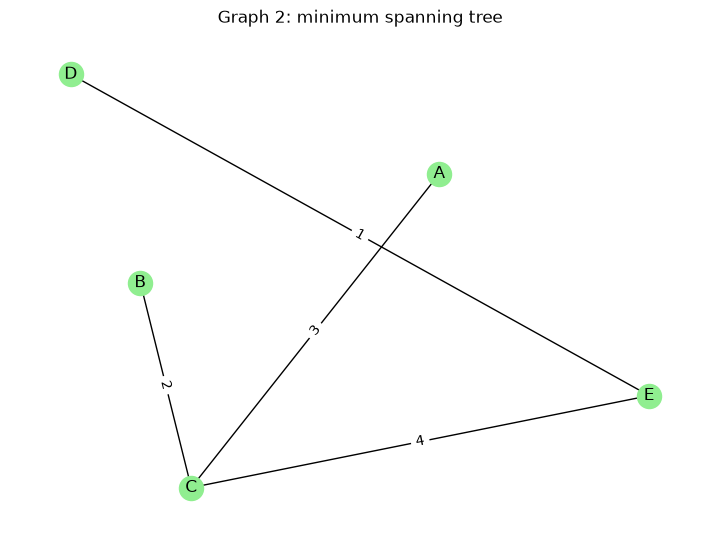

In [12]:
plt.figure(figsize=(7, 5))
nx.draw(mst2, positions2, with_labels=True, node_color="lightgreen")
weights2 = nx.get_edge_attributes(mst2, "weight")
nx.draw_networkx_edge_labels(mst2, positions2, edge_labels=weights2)
plt.title("Graph 2: minimum spanning tree")
plt.axis("off")
plt.show()

I check that the tree has 5 nodes and 4 edges, is connected and has no cycles.

A loop adds the selected edge weights and the expected total is 10.

In [13]:
print("Number of nodes:", mst2.number_of_nodes())
print("Number of edges:", mst2.number_of_edges())
print("Is a tree:", nx.is_tree(mst2))
total_weight2 = 0

for node1, node2 in mst2.edges():
    weight = mst2[node1][node2]["weight"]
    total_weight2 = total_weight2 + weight
print("Total weight:", total_weight2)

Number of nodes: 5
Number of edges: 4
Is a tree: True
Total weight: 10
